# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [23]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DOSSIER = Path("donnees")
brut = pd.read_csv(DOSSIER / "consommation_brut.csv")

print("Forme :", brut.shape)
print("Types :\n", brut.dtypes)
print("Valeurs manquantes :\n", brut.isna().sum())
print("Lignes en double :", brut.duplicated().sum())

Forme : (300, 4)
Types :
 mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object
Valeurs manquantes :
 mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64
Lignes en double : 12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [24]:
print("Écritures différentes :", brut["quartier"].nunique())
print("Exemples :", sorted(brut["quartier"].dropna().unique())[:12])

Écritures différentes : 43
Exemples : [' Bas-Peu-de-Chose', ' Carénage', ' Delmas 33', ' Delmas 65', ' Delmas 75', ' Morne Calvaire', ' Petite-Anse', ' Place Saint-Pierre', ' Thomassin', 'BAS-PEU-DE-CHOSE', 'BOIS-VERNA', 'Bas-Peu-de-Chose']


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [25]:
kwh_convertible = pd.to_numeric(brut["kwh"], errors="coerce")
valeurs_invalides = brut.loc[brut["kwh"].notna() & kwh_convertible.isna(), "kwh"]
print("Valeurs non convertibles :")
print(valeurs_invalides.value_counts().head(15))

Valeurs non convertibles :
kwh
260360 kWh    2
154 720       2
201690 kWh    2
139230 kWh    2
184410 kWh    1
206280 kWh    1
215140 kWh    1
251 900       1
274520 kWh    1
301740 kWh    1
233010 kWh    1
155930 kWh    1
212510 kWh    1
424110 kWh    1
299610 kWh    1
Name: count, dtype: int64


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [26]:
propre = brut.copy()
propre["kwh"] = (
    propre["kwh"]
    .str.replace("kWh", "", regex=False)
    .str.replace(" ", "", regex=False)
)
propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")
print("Valeurs manquantes après conversion :", propre["kwh"].isna().sum())

Valeurs manquantes après conversion : 9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [27]:
quartiers = pd.read_csv(DOSSIER / "quartiers.csv")
noms_officiels = quartiers["quartier"].tolist()
correspondance = {nom.casefold(): nom for nom in noms_officiels}
propre["quartier"] = propre["quartier"].str.strip().str.casefold().map(correspondance)
print("Quartiers après harmonisation :", propre["quartier"].nunique())
print("Noms non reconnus :", propre["quartier"].isna().sum())

Quartiers après harmonisation : 12
Noms non reconnus : 0


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [28]:
propre = propre.drop_duplicates()
propre = propre.dropna(subset=["kwh"]).copy()
print("Forme après suppression des doublons et kWh manquants :", propre.shape)

Forme après suppression des doublons et kWh manquants : (279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [29]:
mediane_quartier = propre.groupby("quartier")["kwh"].transform("median")
anomalies = propre["kwh"] > 3 * mediane_quartier
print("Relevés à corriger :")
print(propre.loc[anomalies, ["mois", "quartier", "kwh"]])
propre.loc[anomalies, "kwh"] = propre.loc[anomalies, "kwh"] / 10
propre["kwh"] = propre["kwh"].astype(int)
print("Maximum après correction :", propre["kwh"].max())

Relevés à corriger :
        mois        quartier        kwh
90   2025-02       Delmas 33  3602600.0
140  2025-02       Delmas 75  2012700.0
200  2024-02  Morne Calvaire  1439200.0
251  2024-01          Rue 15   997700.0
Maximum après correction : 742780


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [30]:
reference = pd.read_csv(DOSSIER / "consommation.csv")
cles_valides = propre[["mois", "quartier"]]
reference = reference.merge(cles_valides, on=["mois", "quartier"], how="inner", validate="one_to_one")
colonnes = propre.columns
propre = propre.sort_values(["mois", "quartier"]).reset_index(drop=True)
reference = reference[colonnes].sort_values(["mois", "quartier"]).reset_index(drop=True)
print("Forme comparée :", propre.shape, reference.shape)
print("Identique au fichier de référence :", propre.equals(reference))
assert propre.equals(reference), "Le nettoyage diffère du fichier de référence."

Forme comparée : (279, 4) (279, 4)
Identique au fichier de référence : True


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [31]:
print("Lignes avant la jointure :", len(propre))
avec_quartiers = propre.merge(quartiers, on="quartier", how="left", validate="many_to_one")
print("Lignes après la jointure :", len(avec_quartiers))
avec_quartiers["kwh_par_abonne"] = (avec_quartiers["kwh"] / avec_quartiers["abonnes"]).round(1)
avec_quartiers["annee"] = avec_quartiers["mois"].str[:4].astype(int)
print(
    "Bas-Peu-de-Chose, 2024-01 :",
    avec_quartiers.loc[
        (avec_quartiers["quartier"] == "Bas-Peu-de-Chose")
        & (avec_quartiers["mois"] == "2024-01"),
        "kwh_par_abonne",
    ].iloc[0],
)

Lignes avant la jointure : 279
Lignes après la jointure : 279
Bas-Peu-de-Chose, 2024-01 : 85.8


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [32]:
print("Lignes avant la jointure météo :", len(avec_quartiers))
meteo = pd.read_csv(DOSSIER / "meteo.csv")
avec_meteo = avec_quartiers.merge(
    meteo,
    on=["mois", "commune"],
    how="left",
    validate="many_to_one",
)
print("Lignes après la jointure météo :", len(avec_meteo))
print("Températures manquantes :", avec_meteo["temperature_c"].isna().sum())
assert avec_meteo["temperature_c"].notna().all()

Lignes avant la jointure météo : 279
Lignes après la jointure météo : 279
Températures manquantes : 0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [33]:
fichier_propre = DOSSIER / "consommation_propre.csv"
avec_meteo.to_csv(fichier_propre, index=False)
consommation_propre = pd.read_csv(fichier_propre)
print("Fichier écrit :", fichier_propre)
print("Forme relue :", consommation_propre.shape)
assert consommation_propre.shape == (279, 11)

Fichier écrit : donnees\consommation_propre.csv
Forme relue : (279, 11)


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

Moyenne par type (kWh/abonné) :
 type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64
Classement des quartiers (kWh/abonné) :
 quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64


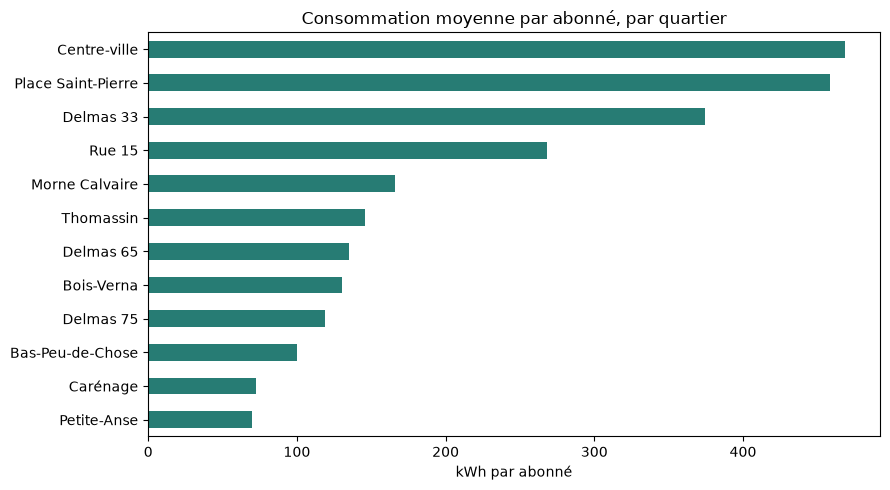

In [34]:
moyenne_type = avec_meteo.groupby("type")["kwh_par_abonne"].mean().sort_values(ascending=False)
classement_quartiers = (
    avec_meteo.groupby("quartier")["kwh_par_abonne"]
    .mean()
    .sort_values(ascending=False)
)
print("Moyenne par type (kWh/abonné) :\n", moyenne_type.round(1))
print("Classement des quartiers (kWh/abonné) :\n", classement_quartiers.round(1))
classement_quartiers.sort_values().plot.barh(figsize=(9, 5), color="#277c74")
plt.xlabel("kWh par abonné")
plt.ylabel("")
plt.title("Consommation moyenne par abonné, par quartier")
plt.tight_layout()
plt.show()

**Ce qu'on en conclut :** Les quartiers commerciaux consomment en moyenne 393,2 kWh par abonné, contre 117,4 pour les quartiers résidentiels. Centre-ville (468,7), Place Saint-Pierre (458,3) et Delmas 33 (374,4) sont en tête.

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

Totaux et évolution par commune :
                 2024 (millions de kWh)  2025 (millions de kWh)  Hausse (%)
commune                                                                   
Cap-Haïtien                       4.59                    5.62        22.5
Pétion-Ville                      8.60                    9.68        12.6
Port-au-Prince                   10.09                   10.31         2.3
Delmas                           11.61                   11.74         1.1
Totaux exacts Cap-Haïtien : {2024: 4587550, 2025: 5617740}
Hausse exacte Cap-Haïtien : 22.45621301130234


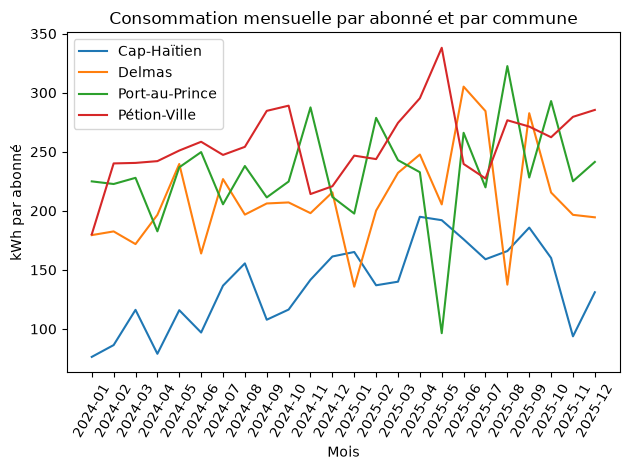

In [35]:
totaux_commune_annee = avec_meteo.pivot_table(
    index="commune", columns="annee", values="kwh", aggfunc="sum"
).sort_index()
hausse_pct = (totaux_commune_annee[2025] / totaux_commune_annee[2024] - 1) * 100
resume_annuel = pd.DataFrame(
    {
        "2024 (millions de kWh)": (totaux_commune_annee[2024] / 1_000_000).round(2),
        "2025 (millions de kWh)": (totaux_commune_annee[2025] / 1_000_000).round(2),
        "Hausse (%)": hausse_pct.round(1),
    }
).sort_values("Hausse (%)", ascending=False)
print("Totaux et évolution par commune :\n", resume_annuel)
print("Totaux exacts Cap-Haïtien :", totaux_commune_annee.loc["Cap-Haïtien"].to_dict())
print("Hausse exacte Cap-Haïtien :", hausse_pct.loc["Cap-Haïtien"])

mensuel_abonne = (
    avec_meteo.groupby(["commune", "mois"], as_index=False)["kwh_par_abonne"]
    .mean()
)
for commune, donnees_commune in mensuel_abonne.groupby("commune"):
    plt.plot(donnees_commune["mois"], donnees_commune["kwh_par_abonne"], label=commune)
plt.xlabel("Mois")
plt.ylabel("kWh par abonné")
plt.title("Consommation mensuelle par abonné et par commune")
plt.xticks(rotation=60)
plt.legend()
plt.tight_layout()
plt.show()

**Ce qu'on en conclut :** Cap-Haïtien progresse le plus, de 4,59 à 5,62 millions de kWh. Le calcul à partir des totaux exacts donne +22,5 % (22,456 % avant arrondi), tandis que l'attendu du sujet indique +22,4 %; Delmas progresse le moins, de +1,1 %.

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

Corrélation avec les heures de courant : 0.76
Corrélation avec la température : -0.15


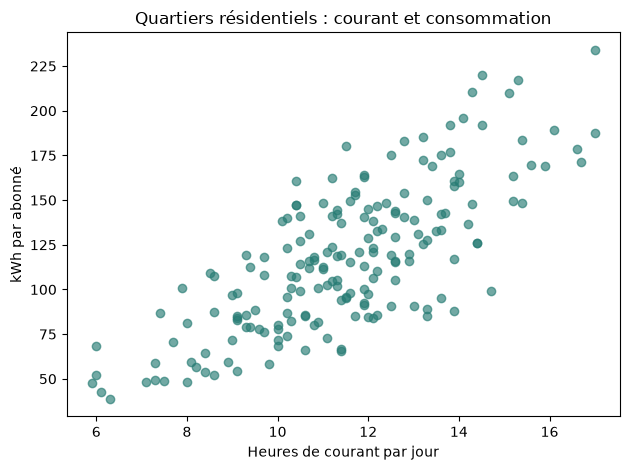

In [36]:
residentiel = avec_meteo.loc[avec_meteo["type"] == "Résidentiel"]
correlations = residentiel[["kwh_par_abonne", "heures_courant", "temperature_c"]].corr()
correlation_courant = correlations.loc["kwh_par_abonne", "heures_courant"]
correlation_temperature = correlations.loc["kwh_par_abonne", "temperature_c"]
print(f"Corrélation avec les heures de courant : {correlation_courant:.2f}")
print(f"Corrélation avec la température : {correlation_temperature:.2f}")
plt.scatter(residentiel["heures_courant"], residentiel["kwh_par_abonne"], alpha=0.65, color="#277c74")
plt.xlabel("Heures de courant par jour")
plt.ylabel("kWh par abonné")
plt.title("Quartiers résidentiels : courant et consommation")
plt.tight_layout()
plt.show()
assert round(correlation_courant, 2) == 0.76
assert round(correlation_temperature, 2) == -0.15

**Ce qu'on en conclut :** Dans les quartiers résidentiels, la consommation par abonné est davantage associée aux heures de courant (corrélation de 0,76) qu'à la température (−0,15). Cette association ne prouve pas que les heures de courant causent à elles seules la hausse de consommation.

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

Heures de courant par commune :
                 mediane    q1    q3
commune                            
Cap-Haïtien        10.0   8.3  11.7
Delmas             11.9  10.1  13.0
Port-au-Prince     11.6  10.7  13.1
Pétion-Ville       11.6  10.4  13.0


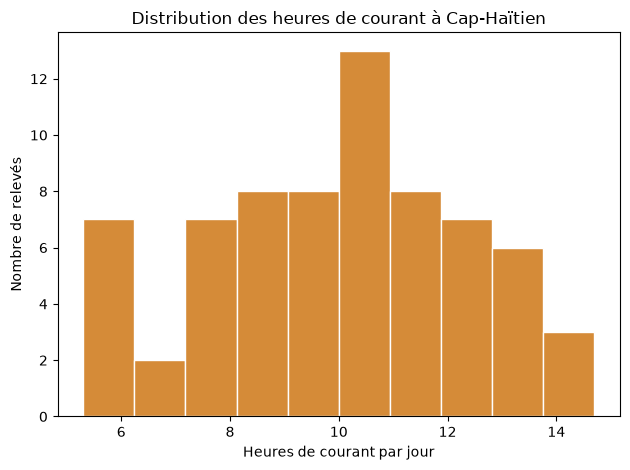

Relevés de 2025 sous 8 heures : 3
   mois  quartier  heures_courant
2025-01 Delmas 33             7.4
2025-08  Carénage             7.3
2025-11    Rue 15             5.9


In [37]:
resume_coupures = avec_meteo.groupby("commune")["heures_courant"].agg(
    mediane="median",
    q1=lambda valeurs: valeurs.quantile(0.25),
    q3=lambda valeurs: valeurs.quantile(0.75),
).round(1)
print("Heures de courant par commune :\n", resume_coupures)
cap_haïtien = avec_meteo.loc[avec_meteo["commune"] == "Cap-Haïtien", "heures_courant"]
plt.hist(cap_haïtien, bins=10, color="#d58b38", edgecolor="white")
plt.xlabel("Heures de courant par jour")
plt.ylabel("Nombre de relevés")
plt.title("Distribution des heures de courant à Cap-Haïtien")
plt.tight_layout()
plt.show()
coupures_longues = avec_meteo.loc[
    (avec_meteo["annee"] == 2025) & (avec_meteo["heures_courant"] < 8),
    ["mois", "quartier", "heures_courant"],
]
print("Relevés de 2025 sous 8 heures :", len(coupures_longues))
print(coupures_longues.to_string(index=False))

**Ce qu'on en conclut :** Cap-Haïtien a la médiane la plus basse, avec 10,0 heures de courant par jour, contre 11,6 à 11,9 heures dans les autres communes. En 2025, trois relevés passent sous 8 heures : Carénage, Delmas 33 et Rue 15.

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [38]:
plus_gros_releves = avec_meteo.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]
print(plus_gros_releves.to_string(index=False))

   mois     quartier       type    kwh
2025-07    Delmas 33 Commercial 742780
2024-11 Centre-ville Commercial 597730
2025-09    Delmas 33 Commercial 591420


**Ce qu'on en conclut :** Les trois consommations les plus élevées sont des relevés commerciaux : Delmas 33 en juillet 2025 (742 780 kWh), Centre-ville en novembre 2024 (597 730 kWh), puis Delmas 33 en septembre 2025 (591 420 kWh).

## 9. Conclusion

Dans les quartiers résidentiels, la consommation par abonné est plus fortement associée aux heures de courant (corrélation de 0,76) qu'à la température (−0,15). Ces résultats suggèrent que la disponibilité du courant suit mieux les variations de consommation observées que la chaleur, sur ces deux années de données. Une corrélation ne prouve toutefois pas un lien de cause à effet et ne permet pas d'écarter l'influence d'autres facteurs.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.